In [2]:
from pathlib import Path
import geopandas as gpd
import h3

caminho = Path("../dados/brutos/bairros/prefeitura_bairro.gpkg")
#print(Path.exists(caminho))
pref_bairro = gpd.read_file(caminho)
pref_bairro.head()


/home/emanu/projetos/ftl-projeto-final/.venv/lib/python3.12/site-packages/pyogrio/geopandas.py:382: UserWarning: More than one layer found in 'prefeitura_bairro.gpkg': 'prefeituras_bairro_a' (default), 'layer_styles'. Specify layer parameter to avoid this warning.
  result = read_func(


,PREF_BAIRR,COD_PBR,ID,QTD_BAIRRO,area,geometry
0,Prefeitura-bairro IV - Itapuã / Ipitanga,IV,4,17,94380440.97,"MULTIPOLYGON (((563183.372 8565464.348, 563137..."
1,Prefeitura-bairro X - Valéria,X,10,4,25325166.31,"MULTIPOLYGON (((560318.999 8574966.432, 560166..."
2,Prefeitura-bairro V - Cidade Baixa,V,5,14,8132459.00,"MULTIPOLYGON (((553769.31 8569249.552, 553767...."
3,Prefeitura-bairro III - Cajazeiras,III,3,17,22160586.15,"MULTIPOLYGON (((566822.94 8573201.26, 566811.8..."
4,Prefeitura-bairro IX - Pau da Lima,IX,9,13,19905726.69,"MULTIPOLYGON (((563789.494 8569538.91, 563559...."


In [3]:
# Reúne os dez recortes em uma única geometria.
limite_salvador = pref_bairro.to_crs(epsg=31984).geometry.union_all()

limite_wgs84 = gpd.GeoSeries(
    [limite_salvador], crs="EPSG:31984"
).to_crs(epsg=4326).iloc[0]

ids_salvador = sorted(set(h3.h3shape_to_cells_experimental(
    h3.geo_to_h3shape(limite_wgs84),
    res=10,
    contain="overlap"
)))

print("Prefeituras-Bairro:", len(pref_bairro))
print("Tipo do recorte:", limite_salvador.geom_type)
print("Recorte válido:", limite_salvador.is_valid)
print("Células candidatas:", len(ids_salvador))

Prefeituras-Bairro: 10
Tipo do recorte: MultiPolygon
Recorte válido: True
Células candidatas: 18317


In [4]:
from shapely.geometry import Polygon

grade_integral = gpd.GeoDataFrame(
    {"h3_id": ids_salvador},
    geometry=[
        Polygon([(lon, lat) for lat, lon in h3.cell_to_boundary(celula)])
        for celula in ids_salvador
    ],
    crs="EPSG:4326",
).to_crs("EPSG:31984")

In [5]:
limite_gdf = gpd.GeoDataFrame(
    geometry=[limite_salvador],
    crs="EPSG:31984",
)

grade_salvador = gpd.clip(
    grade_integral,
    limite_gdf,
    keep_geom_type=True,
)

grade_salvador = grade_salvador.loc[
    grade_salvador.geometry.area > 0
].copy()

area_coberta = grade_salvador.geometry.union_all().area
cobertura = 100 * area_coberta / limite_salvador.area

print("Células após o recorte:", len(grade_salvador))
print("IDs duplicados:", grade_salvador["h3_id"].duplicated().sum())
print("Geometrias inválidas:", (~grade_salvador.geometry.is_valid).sum())
print(f"Cobertura do território: {cobertura:.6f}%")

Células após o recorte: 18317
IDs duplicados: 0
Geometrias inválidas: 0
Cobertura do território: 100.000000%


In [6]:
print("Células na grade integral:", len(grade_integral))
print("CRS:", grade_integral.crs)

Células na grade integral: 18317
CRS: EPSG:31984


In [7]:
caminho_setores = Path("../dados/brutos/populacao/BA_setores_CD2022.gpkg")

setores_ba = gpd.read_file(
    caminho_setores,
    columns=["CD_MUN", "CD_SETOR", "v0001"],
)

setores_salvador = (
    setores_ba.loc[
        setores_ba["CD_MUN"].astype(str).eq("2927408"),
        ["CD_SETOR", "v0001", "geometry"],
    ]
    .to_crs(epsg=31984)
    .dissolve(by="CD_SETOR", aggfunc="first", as_index=False)
)

print("Setores de Salvador:", len(setores_salvador))
print("População total:", setores_salvador["v0001"].sum())
print("CRS:", setores_salvador.crs)

Setores de Salvador: 4542
População total: 2417678
CRS: EPSG:31984


In [8]:
setores_base = setores_salvador[["CD_SETOR", "v0001", "geometry"]].copy()

# Guardar a área de cada setor inteiro antes de recortá-lo.
setores_base["area_setor_m2"] = setores_base.geometry.area

setores_no_recorte = gpd.clip(setores_base, limite_gdf)
setores_no_recorte["area_no_recorte_m2"] = setores_no_recorte.geometry.area

setores_no_recorte = setores_no_recorte.loc[
    setores_no_recorte["area_no_recorte_m2"] > 0
].copy()

setores_no_recorte["pop_no_recorte"] = (
    setores_no_recorte["v0001"]
    * setores_no_recorte["area_no_recorte_m2"]
    / setores_no_recorte["area_setor_m2"]
)

pop_censo = setores_base["v0001"].sum()
pop_referencia = setores_no_recorte["pop_no_recorte"].sum()

print("Setores de Salvador:", len(setores_base))
print("Setores com área no recorte:", len(setores_no_recorte))
print(f"População total dos setores: {pop_censo:,.0f}")
print(f"População estimada no recorte: {pop_referencia:,.2f}")
print(f"Diferença em relação ao total dos setores: {pop_censo - pop_referencia:,.2f}")

Setores de Salvador: 4542
Setores com área no recorte: 4542
População total dos setores: 2,417,678
População estimada no recorte: 2,410,231.79
Diferença em relação ao total dos setores: 7,446.21


In [9]:
fragmentos_salvador = gpd.overlay(
    setores_no_recorte[["CD_SETOR", "v0001", "area_setor_m2", "geometry"]],
    grade_salvador[["h3_id", "geometry"]],
    how="intersection",
    keep_geom_type=True,
)

fragmentos_salvador["pop_fragmento"] = (
    fragmentos_salvador["v0001"]
    * fragmentos_salvador.geometry.area
    / fragmentos_salvador["area_setor_m2"]
)

pop_por_celula = (
    fragmentos_salvador.groupby("h3_id")["pop_fragmento"]
    .sum()
    .rename("pop_estimada")
)

grade_pop_salvador = grade_salvador.join(pop_por_celula, on="h3_id")

# Contar as células sem interseção com setores antes de preencher com zero.
sem_fragmento = grade_pop_salvador["pop_estimada"].isna().sum()
grade_pop_salvador["pop_estimada"] = grade_pop_salvador["pop_estimada"].fillna(0)

pop_grade = grade_pop_salvador["pop_estimada"].sum()

print("Fragmentos setor × H3:", len(fragmentos_salvador))
print("Células na grade final:", len(grade_pop_salvador))
print("Células sem fragmento censitário:", sem_fragmento)
print(f"População estimada na grade: {pop_grade:,.2f}")
print(f"Diferença em relação ao recorte: {pop_grade - pop_referencia:,.6f}")

Fragmentos setor × H3: 43296
Células na grade final: 18317
Células sem fragmento censitário: 49
População estimada na grade: 2,410,231.79
Diferença em relação ao recorte: 0.000000


In [10]:

grade_pop_salvador["tem_fragmento_censitario"] = (
    grade_pop_salvador["h3_id"].isin(pop_por_celula.index)
)

saida = Path("../dados/processados/grade_h3/grade_h3_r10_pop_salvador.gpkg")
saida.parent.mkdir(parents=True, exist_ok=True)

grade_pop_salvador.to_file(
    saida,
    layer="grade_h3_r10_pop_salvador",
    driver="GPKG",
    index=False,
)

# arquivo para conferir o que foi gravado.
grade_salva = gpd.read_file(saida, layer="grade_h3_r10_pop_salvador")

print("Células:", len(grade_salva))
print("CRS:", grade_salva.crs)
print(f"População estimada: {grade_salva['pop_estimada'].sum():,.2f}")
print("Sem fragmento censitário:", (~grade_salva["tem_fragmento_censitario"]).sum())

Células: 18317
CRS: EPSG:31984
População estimada: 2,410,231.79
Sem fragmento censitário: 49


In [11]:
fragmentos_pb = gpd.overlay(
    fragmentos_salvador[["h3_id", "v0001", "area_setor_m2", "geometry"]],
    pref_bairro[["COD_PBR", "PREF_BAIRR", "geometry"]].to_crs(epsg=31984),
    how="intersection",
    keep_geom_type=True,
)

# A referência continua sendo a área do setor censitário inteiro.
fragmentos_pb["pop_estimada_pb"] = (
    fragmentos_pb["v0001"]
    * fragmentos_pb.geometry.area
    / fragmentos_pb["area_setor_m2"]
)

pop_h3_pb = (
    fragmentos_pb.groupby(["COD_PBR", "PREF_BAIRR", "h3_id"], as_index=False)
    ["pop_estimada_pb"].sum()
)

print("Prefeituras-Bairro:", pop_h3_pb["COD_PBR"].nunique())
print(f"População somada nas regiões: {pop_h3_pb['pop_estimada_pb'].sum():,.2f}")
print(f"Diferença em relação à grade: {pop_h3_pb['pop_estimada_pb'].sum() - pop_grade:,.6f}")

Prefeituras-Bairro: 10
População somada nas regiões: 2,410,231.80
Diferença em relação à grade: 0.002715


In [12]:
tempos_h3 = gpd.read_file(
    "../dados/processados/acessibilidade/grade_h3_r10_acesso_salvador.gpkg",
    layer="acesso_ubs_usf_salvador",
    columns=["h3_id", "tempo_min"],
    ignore_geometry=True,
)

acesso_pb = pop_h3_pb.merge(
    tempos_h3, on="h3_id", how="left", validate="many_to_one", indicator=True
)

# Um tempo vazio só significa "sem rota" se o ID foi encontrado na grade.
assert acesso_pb["_merge"].eq("both").all(), "Há células sem correspondência na grade."

acesso_pb["pop_ate_20"] = acesso_pb["pop_estimada_pb"].where(
    acesso_pb["tempo_min"].le(20), 0
)
acesso_pb["pop_sem_rota"] = acesso_pb["pop_estimada_pb"].where(
    acesso_pb["tempo_min"].isna(), 0
)

resumo_pb = (
    acesso_pb.groupby(["COD_PBR", "PREF_BAIRR"], as_index=False)
    .agg(
        pop_total=("pop_estimada_pb", "sum"),
        pop_ate_20=("pop_ate_20", "sum"),
        pop_sem_rota=("pop_sem_rota", "sum"),
    )
)

resumo_pb["pct_ate_20"] = 100 * resumo_pb["pop_ate_20"] / resumo_pb["pop_total"]

print(resumo_pb.sort_values("pct_ate_20").round(2).to_string(index=False))

pct_municipal = 100 * resumo_pb["pop_ate_20"].sum() / resumo_pb["pop_total"].sum()
print(f"\nCobertura municipal reconstituída: {pct_municipal:.2f}%")

COD_PBR                                       PREF_BAIRR  pop_total  pop_ate_20  pop_sem_rota  pct_ate_20
     IV         Prefeitura-bairro IV - Itapuã / Ipitanga  386585.97   232665.33       3710.33       60.18
     VI            Prefeitura-bairro VI - Barra / Pituba  322348.27   196056.96        835.75       60.82
      X                    Prefeitura-bairro X - Valéria   76518.14    50765.70        980.93       66.34
    III               Prefeitura-bairro III - Cajazeiras  191965.18   155596.65       1080.06       81.05
     IX              Prefeitura-bairro IX -  Pau da Lima  173315.89   145035.70       1171.53       83.68
   VIII Prefeitura-bairro VIII - Cabula / Tancredo Neves  317896.44   274538.72       1101.51       86.36
      I            Prefeitura-bairro I - Centro / Brotas  238643.08   206230.05       2027.00       86.42
      V               Prefeitura-bairro V - Cidade Baixa  146910.15   129500.97         35.13       88.15
     II          Prefeitura-bairro II - Subúrb

In [13]:


resumo_pb["pop_fora_20"] = resumo_pb["pop_total"] - resumo_pb["pop_ate_20"]

saida_pb = Path("../resultados/tabelas/acesso_ubs_usf_por_prefeitura_bairro.csv")
saida_pb.parent.mkdir(parents=True, exist_ok=True)

resumo_pb.sort_values("pct_ate_20").to_csv(
    saida_pb, index=False, sep=";", decimal=",", encoding="utf-8-sig"
)

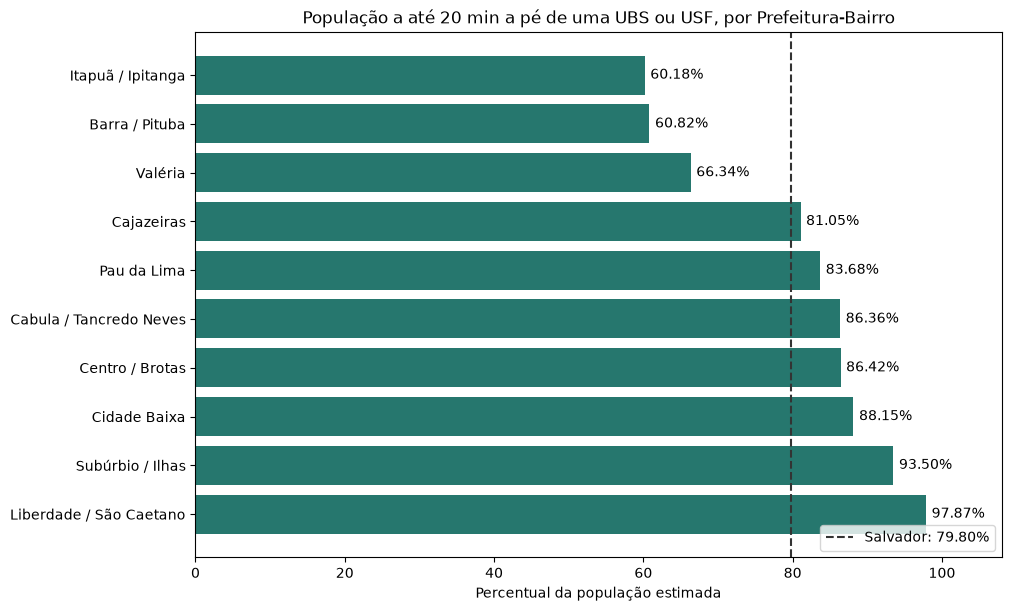

In [14]:
from pathlib import Path
import matplotlib.pyplot as plt

dados_grafico = resumo_pb.sort_values("pct_ate_20").copy()
rotulos = dados_grafico["PREF_BAIRR"].str.split(" - ", n=1).str[-1].str.strip()

referencia = 100 * resumo_pb["pop_ate_20"].sum() / resumo_pb["pop_total"].sum()

fig, ax = plt.subplots(figsize=(10, 6), layout="constrained")
barras = ax.barh(
    rotulos,
    dados_grafico["pct_ate_20"],
    color="#26776e",
)

ax.invert_yaxis()
ax.bar_label(barras, fmt="%.2f%%", padding=4)
ax.axvline(
    referencia, color="#333333", linestyle="--",
    label=f"Salvador: {referencia:.2f}%",
)
ax.set_xlim(0, 108)  # Espaço para os rótulos; o eixo termina em 100%.
ax.set_xticks(range(0, 101, 20))
ax.set_xlabel("Percentual da população estimada")
ax.set_title("População a até 20 min a pé de uma UBS ou USF, por Prefeitura-Bairro")
ax.legend(loc="lower right")

saida = Path("../resultados/graficos/cobertura_20_min_por_prefeitura_bairro.png")
saida.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(saida, dpi=200, bbox_inches="tight", facecolor="white")
plt.show()

In [15]:
setor_pb = gpd.overlay(
    setores_base[["CD_SETOR", "v0001", "area_setor_m2", "geometry"]],
    pref_bairro[["COD_PBR", "PREF_BAIRR", "geometry"]].to_crs(epsg=31984),
    how="intersection",
    keep_geom_type=True,
)

setor_pb["fracao_area"] = setor_pb.geometry.area / setor_pb["area_setor_m2"]
setor_pb["pop_estimada_pb"] = setor_pb["v0001"] * setor_pb["fracao_area"]

saida_setor_pb = Path("../dados/processados/renda/setores_por_prefeitura_bairro.csv")
saida_setor_pb.parent.mkdir(parents=True, exist_ok=True)

setor_pb[
    ["CD_SETOR", "COD_PBR", "PREF_BAIRR", "fracao_area", "pop_estimada_pb"]
].to_csv(saida_setor_pb, index=False)

print("Prefeituras-Bairro:", setor_pb["COD_PBR"].nunique())
print("Setores únicos:", setor_pb["CD_SETOR"].nunique())
print(f"População estimada no recorte: {setor_pb['pop_estimada_pb'].sum():,.2f}")

Prefeituras-Bairro: 10
Setores únicos: 4542
População estimada no recorte: 2,410,231.80


In [16]:
from pathlib import Path

arquivo_pop_h3_pb = Path(
    "../dados/processados/populacao/pop_h3_por_prefeitura_bairro.csv"
)
arquivo_pop_h3_pb.parent.mkdir(parents=True, exist_ok=True)
pop_h3_pb.to_csv(arquivo_pop_h3_pb, index=False)

In [17]:
auditoria_recorte = setores_base[
    ["CD_SETOR", "v0001", "area_setor_m2"]
].merge(
    setores_no_recorte[["CD_SETOR", "area_no_recorte_m2", "pop_no_recorte"]],
    on="CD_SETOR",
    how="left",
    validate="one_to_one",
)

sem_area_no_recorte = auditoria_recorte["area_no_recorte_m2"].isna()
print("Setores sem área no recorte:", sem_area_no_recorte.sum())

# Um setor sem interseção contribui com zero para o recorte.
auditoria_recorte[["area_no_recorte_m2", "pop_no_recorte"]] = (
    auditoria_recorte[["area_no_recorte_m2", "pop_no_recorte"]].fillna(0)
)

auditoria_recorte["pct_area_fora"] = 100 * (
    1 - auditoria_recorte["area_no_recorte_m2"] / auditoria_recorte["area_setor_m2"]
)
auditoria_recorte["pop_estimada_fora"] = (
    auditoria_recorte["v0001"] - auditoria_recorte["pop_no_recorte"]
)

print(f"População nos setores inteiros: {auditoria_recorte['v0001'].sum():,.2f}")
print(f"População estimada após o recorte: {auditoria_recorte['pop_no_recorte'].sum():,.2f}")
print(f"Parcela estimada fora do recorte: {auditoria_recorte['pop_estimada_fora'].sum():,.2f}")
print(f"População estimada na grade H3: {pop_grade:,.2f}")

print("\n10 setores que mais contribuem para a diferença:")
print(
    auditoria_recorte.nlargest(10, "pop_estimada_fora")[
        ["CD_SETOR", "v0001", "pct_area_fora", "pop_estimada_fora"]
    ].round(2).to_string(index=False)
)

Setores sem área no recorte: 0
População nos setores inteiros: 2,417,678.00
População estimada após o recorte: 2,410,231.79
Parcela estimada fora do recorte: 7,446.21
População estimada na grade H3: 2,410,231.79

10 setores que mais contribuem para a diferença:
       CD_SETOR  v0001  pct_area_fora  pop_estimada_fora
292740805100014    822          51.21             420.93
292740805150049   1054          22.64             238.64
292740805130130    649          24.17             156.88
292740805090267    881          16.91             149.00
292740805100004    703          21.05             148.01
292740805090217    757          15.46             117.03
292740805130165    558          20.94             116.83
292740805270375    560          20.85             116.78
292740805060497    342          33.83             115.70
292740805090072    935          12.25             114.55


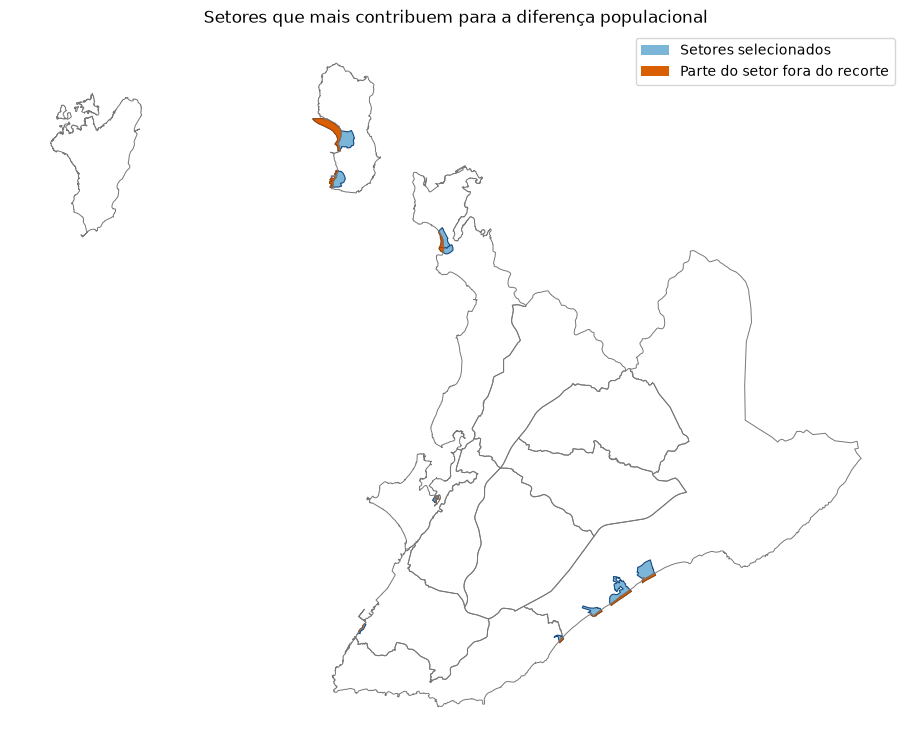

In [19]:

from matplotlib.patches import Patch

top10 = auditoria_recorte.nlargest(10, "pop_estimada_fora")

setores_top10 = setores_base.loc[
    setores_base["CD_SETOR"].isin(top10["CD_SETOR"])
].copy()

# Conserva apenas a parte de cada setor que ficou fora do recorte.
partes_fora = setores_top10.copy()
partes_fora["geometry"] = setores_top10.geometry.difference(limite_salvador)

fig, ax = plt.subplots(figsize=(9, 9), layout="constrained")

pref_bairro.to_crs(setores_top10.crs).boundary.plot(
    ax=ax, color="#777777", linewidth=0.7
)
setores_top10.plot(ax=ax, color="#7BB6D9", edgecolor="#174A7E", linewidth=0.8)
partes_fora.plot(ax=ax, color="#D95F02", edgecolor="#A84400", linewidth=0.7)

ax.legend(handles=[
    Patch(facecolor="#7BB6D9", label="Setores selecionados"),
    Patch(facecolor="#D95F02", label="Parte do setor fora do recorte"),
])
ax.set_title("Setores que mais contribuem para a diferença populacional")
ax.set_axis_off()
plt.show()

In [20]:
# As geometrias devem estar em EPSG:31984 para medir áreas em m².
assert setores_base.crs.to_epsg() == 31984
assert grade_salvador.crs == setores_base.crs

limite_setores = setores_base.geometry.union_all()
limite_grade = grade_salvador.geometry.union_all()

setores_fora_pb = limite_setores.difference(limite_salvador)
pb_fora_setores = limite_salvador.difference(limite_setores)
recorte_sem_h3 = limite_salvador.difference(limite_grade)

print(f"Área da malha de setores fora das PB: {setores_fora_pb.area / 1_000_000:,.4f} km²")
print(f"Área das PB fora da malha de setores: {pb_fora_setores.area / 1_000_000:,.4f} km²")
print(f"Área do recorte sem cobertura H3: {recorte_sem_h3.area:,.2f} m²")

Área da malha de setores fora das PB: 389.5475 km²
Área das PB fora da malha de setores: 0.7206 km²
Área do recorte sem cobertura H3: 0.00 m²


In [21]:
auditoria_recorte["area_fora_km2"] = (
    auditoria_recorte["area_setor_m2"]
    - auditoria_recorte["area_no_recorte_m2"]
) / 1_000_000

print(f"Área da união dos setores: {limite_setores.area / 1_000_000:,.4f} km²")
print(f"Área da união das Prefeituras-Bairro: {limite_salvador.area / 1_000_000:,.4f} km²")

print("\nCinco setores com maior área fora do recorte:")
print(
    auditoria_recorte.nlargest(5, "area_fora_km2")[
        ["CD_SETOR", "v0001", "area_fora_km2", "pct_area_fora", "pop_estimada_fora"]
    ].round(4).to_string(index=False)
)

Área da união dos setores: 692.9364 km²
Área da união das Prefeituras-Bairro: 304.1096 km²

Cinco setores com maior área fora do recorte:
       CD_SETOR  v0001  area_fora_km2  pct_area_fora  pop_estimada_fora
292740805100008      0       385.6253        99.9479             0.0000
292740805100016    410         0.7656        20.0174            82.0712
292740805100014    822         0.5036        51.2078           420.9282
292740805100019    206         0.2118        16.4391            33.8645
292740805100012      4         0.1739         2.5077             0.1003
